# Load and Read Dataset

In [1]:
import warnings
import os

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

warnings.simplefilter("ignore")

In [2]:
import pandas as pd

# Load feature names
features = pd.read_csv(
    "features.txt",
    sep=r"\s+",
    header=None,
    names=["index", "feature"]
)

# Load activity labels
activity_labels = pd.read_csv(
    "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"]
)

# Load training data
X_train = pd.read_csv(
    "train/X_train.txt",
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    "train/y_train.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)

# Load testing data
X_test = pd.read_csv(
    "test/X_test.txt",
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    "test/y_test.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

print("\nNumber of features:", len(features))
print("Number of activities:", len(activity_labels))

X_train shape: (7352, 561)
y_train shape: (7352, 1)
X_test shape : (2947, 561)
y_test shape : (2947, 1)

Number of features: 561
Number of activities: 6


# Analysis features and Activities

In [3]:
# Display the first 20 feature names
print("First 20 Features:")
display(features.head(20))

# Display all activity labels
print("\nActivity Labels:")
display(activity_labels)

# Display the first 10 rows of training data
print("\nFirst 10 rows of X_train:")
display(X_train.iloc[:10, :10])

# Display the first 10 target values
print("\nFirst 10 target values:")
display(y_train.head(10))

First 20 Features:


,index,feature
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y
5,6,tBodyAcc-std()-Z
6,7,tBodyAcc-mad()-X
7,8,tBodyAcc-mad()-Y
8,9,tBodyAcc-mad()-Z
9,10,tBodyAcc-max()-X



Activity Labels:


,activity_id,activity
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING



First 10 rows of X_train:


,0,1,2,3,4,5,6,7,8,9
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469
5,0.277199,-0.010098,-0.105137,-0.997335,-0.990487,-0.995420,-0.997627,-0.990218,-0.995549,-0.942469
6,0.279454,-0.019641,-0.110022,-0.996921,-0.967186,-0.983118,-0.997003,-0.966097,-0.983116,-0.940987
7,0.277432,-0.030488,-0.125360,-0.996559,-0.966728,-0.981585,-0.996485,-0.966313,-0.982982,-0.940987
8,0.277293,-0.021751,-0.120751,-0.997328,-0.961245,-0.983672,-0.997596,-0.957236,-0.984379,-0.940598
9,0.280586,-0.009960,-0.106065,-0.994803,-0.972758,-0.986244,-0.995405,-0.973663,-0.985642,-0.940028



First 10 target values:


,activity_id
0,5
1,5
2,5
3,5
4,5
5,5
6,5
7,5
8,5
9,5


In [4]:

# Step 3: Data Quality Analysis


print("=== Dataset Information ===")
print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])
print("Number of features:", X_train.shape[1])


# 1. Missing Values

print("\n=== Missing Values ===")
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test :", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum().sum())
print("Missing values in y_test :", y_test.isnull().sum().sum())


# 2. Duplicate Rows

print("\n=== Duplicate Rows ===")
print("Duplicate rows in X_train:", X_train.duplicated().sum())
print("Duplicate rows in X_test :", X_test.duplicated().sum())


# 3. Data Types

print("\n=== Data Types ===")
print(X_train.dtypes.value_counts())


# 4. Target Distribution

print("\n=== Training Target Distribution ===")
print(y_train["activity_id"].value_counts().sort_index())

print("\n=== Testing Target Distribution ===")
print(y_test["activity_id"].value_counts().sort_index())


# 5. Feature Statistics

print("\n=== Feature Statistics ===")
display(X_train.describe().T.head(10))

=== Dataset Information ===
Training samples : 7352
Testing samples  : 2947
Number of features: 561

=== Missing Values ===
Missing values in X_train: 0
Missing values in X_test : 0
Missing values in y_train: 0
Missing values in y_test : 0

=== Duplicate Rows ===
Duplicate rows in X_train: 0
Duplicate rows in X_test : 0

=== Data Types ===
float64    561
Name: count, dtype: int64

=== Training Target Distribution ===
activity_id
1    1226
2    1073
3     986
4    1286
5    1374
6    1407
Name: count, dtype: int64

=== Testing Target Distribution ===
activity_id
1    496
2    471
3    420
4    491
5    532
6    537
Name: count, dtype: int64

=== Feature Statistics ===


,count,mean,std,min,25%,50%,75%,max
0,7352.0,0.274488,0.070261,-1.000000,0.262975,0.277193,0.288461,1.000000
1,7352.0,-0.017695,0.040811,-1.000000,-0.024863,-0.017219,-0.010783,1.000000
2,7352.0,-0.109141,0.056635,-1.000000,-0.120993,-0.108676,-0.097794,1.000000
3,7352.0,-0.605438,0.448734,-1.000000,-0.992754,-0.946196,-0.242813,1.000000
4,7352.0,-0.510938,0.502645,-0.999873,-0.978129,-0.851897,-0.034231,0.916238
5,7352.0,-0.604754,0.418687,-1.000000,-0.980233,-0.859365,-0.262415,1.000000
6,7352.0,-0.630512,0.424073,-1.000000,-0.993591,-0.950709,-0.292680,1.000000
7,7352.0,-0.526907,0.485942,-1.000000,-0.978162,-0.857328,-0.066701,0.967664
8,7352.0,-0.606150,0.414122,-1.000000,-0.980251,-0.857143,-0.265671,1.000000
9,7352.0,-0.468604,0.544547,-1.000000,-0.936219,-0.881637,-0.017129,1.000000


# Build Base Logistic Regression Model with Evaluate it

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X_opt, X_val, y_opt, y_val = train_test_split(
    X_train,
    y_train["activity_id"],
    test_size=0.20,
    random_state=42,
    stratify=y_train["activity_id"]
)

print("Optimization training samples:", X_opt.shape[0])
print("Validation samples:", X_val.shape[0])
print("Number of features:", X_opt.shape[1])

Optimization training samples: 5881
Validation samples: 1471
Number of features: 561


In [6]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_opt, y_opt)

baseline_predictions = baseline_model.predict(X_val)

baseline_accuracy = accuracy_score(y_val, baseline_predictions)
baseline_f1 = f1_score(y_val, baseline_predictions, average="macro")

print("Baseline Results")
print("Number of features:", X_opt.shape[1])
print("Validation Accuracy:", baseline_accuracy)
print("Validation Macro-F1:", baseline_f1)

Baseline Results
Number of features: 561
Validation Accuracy: 0.9809653297076818
Validation Macro-F1: 0.9822455197681924


# Random Forest

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

baseline_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

baseline_rf.fit(X_opt, y_opt)

training_time = time.time() - start_time

start_time = time.time()

rf_predictions = baseline_rf.predict(X_val)

prediction_time = time.time() - start_time

rf_accuracy = accuracy_score(y_val, rf_predictions)
rf_f1 = f1_score(y_val, rf_predictions, average="macro")

print("Random Forest Baseline Results")
print("Number of features:", X_opt.shape[1])
print("Validation Accuracy:", rf_accuracy)
print("Validation Macro-F1:", rf_f1)
print("Training Time:", training_time, "seconds")
print("Prediction Time:", prediction_time, "seconds")

Random Forest Baseline Results
Number of features: 561
Validation Accuracy: 0.981645139360979
Validation Macro-F1: 0.9818526690724808
Training Time: 3.315734386444092 seconds
Prediction Time: 0.13132047653198242 seconds


# Algorithms

## GA

In [8]:
import numpy as np
import pandas as pd
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


total_features = X_opt.shape[1]
lambda_penalty = 0.01


def evaluate_solution(solution, max_features):
    selected_features = np.where(solution == 1)[0]
    number_selected = len(selected_features)

    if number_selected == 0:
        return float("inf"), 0, 0, 0

    if number_selected > max_features:
        return float("inf"), number_selected, 0, 0

    X_opt_selected = X_opt.iloc[:, selected_features]
    X_val_selected = X_val.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_opt_selected, y_opt)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions, average="macro")

    error = 1 - accuracy
    feature_ratio = number_selected / total_features

    fitness = error + lambda_penalty * feature_ratio

    return fitness, number_selected, accuracy, f1


def create_individual(max_features):
    solution = np.zeros(total_features, dtype=int)

    number_selected = np.random.randint(
        1,
        max_features + 1
    )

    selected_indices = np.random.choice(
        total_features,
        size=number_selected,
        replace=False
    )

    solution[selected_indices] = 1

    return solution


def create_population(population_size, max_features):
    population = []

    for _ in range(population_size):
        population.append(
            create_individual(max_features)
        )

    return np.array(population)


def evaluate_population(population, max_features):
    fitness_values = []
    feature_counts = []
    accuracies = []
    f1_scores = []

    for solution in population:
        fitness, feature_count, accuracy, f1 = evaluate_solution(
            solution,
            max_features
        )

        fitness_values.append(fitness)
        feature_counts.append(feature_count)
        accuracies.append(accuracy)
        f1_scores.append(f1)

    return (
        np.array(fitness_values),
        np.array(feature_counts),
        np.array(accuracies),
        np.array(f1_scores)
    )


def tournament_selection(
    population,
    fitness_values,
    tournament_size=3
):
    selected_indices = []

    population_size = len(population)

    for _ in range(population_size):
        candidates = np.random.choice(
            population_size,
            size=tournament_size,
            replace=False
        )

        winner = candidates[
            np.argmin(fitness_values[candidates])
        ]

        selected_indices.append(winner)

    return population[selected_indices].copy()


def crossover(
    parent1,
    parent2,
    crossover_rate=0.8
):
    child1 = parent1.copy()
    child2 = parent2.copy()

    if np.random.rand() < crossover_rate:
        point = np.random.randint(
            1,
            total_features - 1
        )

        child1[:point] = parent1[:point]
        child1[point:] = parent2[point:]

        child2[:point] = parent2[:point]
        child2[point:] = parent1[point:]

    return child1, child2


def repair_solution(solution, max_features):
    selected_indices = np.where(solution == 1)[0]

    if len(selected_indices) > max_features:
        remove_count = len(selected_indices) - max_features

        remove_indices = np.random.choice(
            selected_indices,
            size=remove_count,
            replace=False
        )

        solution[remove_indices] = 0

    if solution.sum() == 0:
        random_index = np.random.randint(total_features)
        solution[random_index] = 1

    return solution


def mutate(
    solution,
    mutation_rate=0.01
):
    mutation_mask = (
        np.random.rand(total_features) < mutation_rate
    )

    solution[mutation_mask] = (
        1 - solution[mutation_mask]
    )

    return solution


def run_genetic_algorithm(
    problem_name,
    max_features,
    population_size=20,
    generations=20,
    crossover_rate=0.8,
    mutation_rate=0.01,
    tournament_size=3,
    elitism=1,
    random_seed=42
):
    np.random.seed(random_seed)

    start_time = time.time()

    population = create_population(
        population_size,
        max_features
    )

    best_solution = None
    best_fitness = float("inf")
    best_accuracy = 0.0
    best_f1 = 0.0
    best_feature_count = 0

    convergence_history = []

    for generation in range(generations):

        fitness_values, feature_counts, accuracies, f1_scores = (
            evaluate_population(
                population,
                max_features
            )
        )

        generation_best_index = np.argmin(
            fitness_values
        )

        generation_best_fitness = (
            fitness_values[generation_best_index]
        )

        if generation_best_fitness < best_fitness:

            best_fitness = generation_best_fitness

            best_solution = (
                population[generation_best_index].copy()
            )

            best_accuracy = (
                accuracies[generation_best_index]
            )

            best_f1 = (
                f1_scores[generation_best_index]
            )

            best_feature_count = (
                feature_counts[generation_best_index]
            )

        convergence_history.append({
            "Generation": generation + 1,
            "Best Fitness": best_fitness,
            "Best Accuracy": best_accuracy,
            "Best Macro-F1": best_f1,
            "Selected Features": best_feature_count
        })

        print(
            f"Generation {generation + 1}/{generations} | "
            f"Fitness: {best_fitness:.6f} | "
            f"Features: {best_feature_count} | "
            f"Accuracy: {best_accuracy:.4f}"
        )

        selected_population = tournament_selection(
            population,
            fitness_values,
            tournament_size
        )

        new_population = []

        elite_indices = np.argsort(
            fitness_values
        )[:elitism]

        for index in elite_indices:
            new_population.append(
                population[index].copy()
            )

        while len(new_population) < population_size:

            parent_indices = np.random.choice(
                len(selected_population),
                size=2,
                replace=False
            )

            parent1 = selected_population[
                parent_indices[0]
            ]

            parent2 = selected_population[
                parent_indices[1]
            ]

            child1, child2 = crossover(
                parent1,
                parent2,
                crossover_rate
            )

            child1 = mutate(
                child1,
                mutation_rate
            )

            child2 = mutate(
                child2,
                mutation_rate
            )

            child1 = repair_solution(
                child1,
                max_features
            )

            child2 = repair_solution(
                child2,
                max_features
            )

            new_population.append(child1)

            if len(new_population) < population_size:
                new_population.append(child2)

        population = np.array(new_population)

    runtime = time.time() - start_time

    result = {
        "Algorithm": "GA",
        "Problem Size": problem_name,
        "Max Features": max_features,
        "Best Fitness": best_fitness,
        "Selected Features": best_feature_count,
        "Validation Accuracy": best_accuracy,
        "Validation Macro-F1": best_f1,
        "Runtime (seconds)": runtime,
        "Best Solution": best_solution,
        "Convergence": pd.DataFrame(
            convergence_history
        )
    }

    return result

In [9]:
ga_small_result = run_genetic_algorithm(
    problem_name="Small",
    max_features=100,
    population_size=20,
    generations=20,
    crossover_rate=0.8,
    mutation_rate=0.01,
    tournament_size=3,
    elitism=1,
    random_seed=42
)

Generation 1/20 | Fitness: 0.025415 | Features: 91 | Accuracy: 0.9762
Generation 2/20 | Fitness: 0.021892 | Features: 84 | Accuracy: 0.9796
Generation 3/20 | Fitness: 0.019386 | Features: 96 | Accuracy: 0.9823
Generation 4/20 | Fitness: 0.019386 | Features: 96 | Accuracy: 0.9823
Generation 5/20 | Fitness: 0.018778 | Features: 100 | Accuracy: 0.9830
Generation 6/20 | Fitness: 0.018778 | Features: 100 | Accuracy: 0.9830
Generation 7/20 | Fitness: 0.016738 | Features: 100 | Accuracy: 0.9850
Generation 8/20 | Fitness: 0.016023 | Features: 98 | Accuracy: 0.9857
Generation 9/20 | Fitness: 0.016023 | Features: 98 | Accuracy: 0.9857
Generation 10/20 | Fitness: 0.015379 | Features: 100 | Accuracy: 0.9864
Generation 11/20 | Fitness: 0.015379 | Features: 100 | Accuracy: 0.9864
Generation 12/20 | Fitness: 0.014699 | Features: 100 | Accuracy: 0.9871
Generation 13/20 | Fitness: 0.014699 | Features: 100 | Accuracy: 0.9871
Generation 14/20 | Fitness: 0.014699 | Features: 100 | Accuracy: 0.9871
Generat

In [10]:
ga_small_convergence = ga_small_result["Convergence"]

print("GA Small Final Result")
print("Best Fitness:", ga_small_result["Best Fitness"])
print("Selected Features:", ga_small_result["Selected Features"])
print("Validation Accuracy:", ga_small_result["Validation Accuracy"])
print("Validation Macro-F1:", ga_small_result["Validation Macro-F1"])
print("Runtime:", ga_small_result["Runtime (seconds)"], "seconds")

display(ga_small_convergence)

GA Small Final Result
Best Fitness: 0.01469891460694035
Selected Features: 100
Validation Accuracy: 0.9870836165873556
Validation Macro-F1: 0.9873365521748031
Runtime: 760.8035655021667 seconds


,Generation,Best Fitness,Best Accuracy,Best Macro-F1,Selected Features
0,1,0.025415,0.976207,0.976316,91
1,2,0.021892,0.979606,0.979373,84
2,3,0.019386,0.982325,0.982375,96
3,4,0.019386,0.982325,0.982375,96
4,5,0.018778,0.983005,0.983222,100
5,6,0.018778,0.983005,0.983222,100
6,7,0.016738,0.985044,0.985177,100
7,8,0.016023,0.985724,0.985994,98
8,9,0.016023,0.985724,0.985994,98
9,10,0.015379,0.986404,0.986389,100


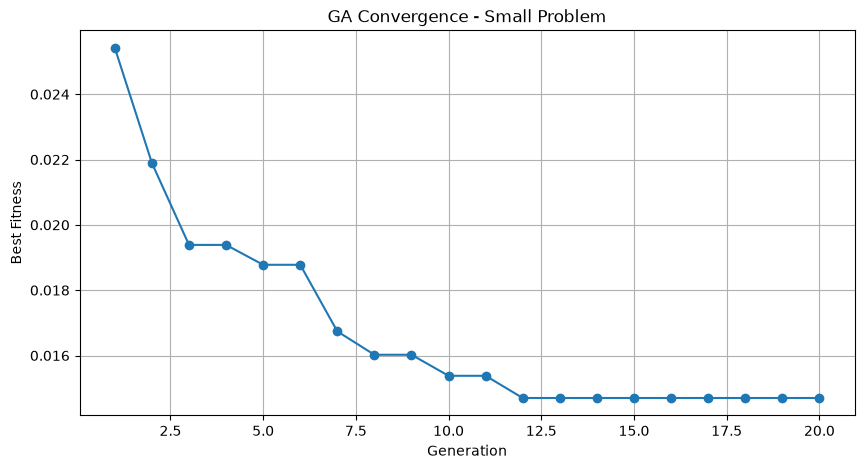

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    ga_small_convergence["Generation"],
    ga_small_convergence["Best Fitness"],
    marker="o"
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("GA Convergence - Small Problem")
plt.grid(True)

plt.show()

In [12]:
ga_medium_result = run_genetic_algorithm(
    problem_name="Medium",
    max_features=300,
    population_size=20,
    generations=20,
    crossover_rate=0.8,
    mutation_rate=0.01,
    tournament_size=3,
    elitism=1,
    random_seed=42
)

Generation 1/20 | Fitness: 0.019262 | Features: 89 | Accuracy: 0.9823
Generation 2/20 | Fitness: 0.018185 | Features: 143 | Accuracy: 0.9844
Generation 3/20 | Fitness: 0.018185 | Features: 143 | Accuracy: 0.9844
Generation 4/20 | Fitness: 0.017882 | Features: 126 | Accuracy: 0.9844
Generation 5/20 | Fitness: 0.017882 | Features: 126 | Accuracy: 0.9844
Generation 6/20 | Fitness: 0.017882 | Features: 126 | Accuracy: 0.9844
Generation 7/20 | Fitness: 0.017882 | Features: 126 | Accuracy: 0.9844
Generation 8/20 | Fitness: 0.017879 | Features: 164 | Accuracy: 0.9850
Generation 9/20 | Fitness: 0.017612 | Features: 149 | Accuracy: 0.9850
Generation 10/20 | Fitness: 0.016145 | Features: 143 | Accuracy: 0.9864
Generation 11/20 | Fitness: 0.015412 | Features: 140 | Accuracy: 0.9871
Generation 12/20 | Fitness: 0.015412 | Features: 140 | Accuracy: 0.9871
Generation 13/20 | Fitness: 0.015412 | Features: 140 | Accuracy: 0.9871
Generation 14/20 | Fitness: 0.015053 | Features: 158 | Accuracy: 0.9878
Ge

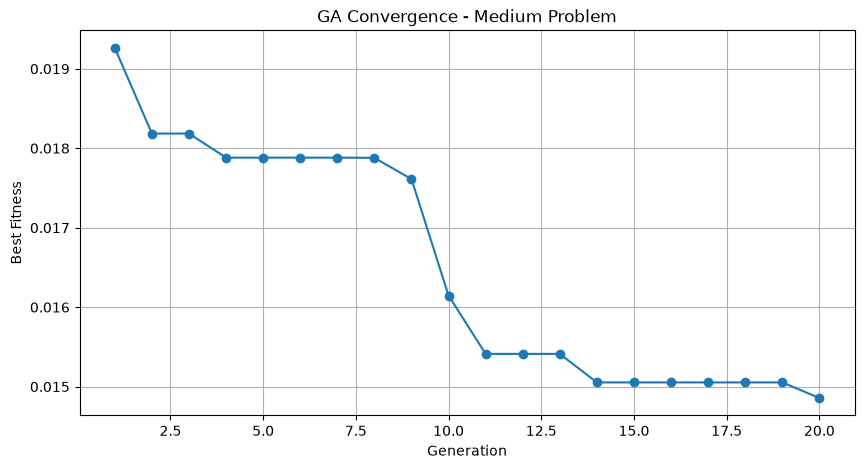

In [13]:
import matplotlib.pyplot as plt

ga_medium_convergence = ga_medium_result["Convergence"]

plt.figure(figsize=(10, 5))

plt.plot(
    ga_medium_convergence["Generation"],
    ga_medium_convergence["Best Fitness"],
    marker="o"
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("GA Convergence - Medium Problem")
plt.grid(True)

plt.show()

In [14]:
ga_large_result = run_genetic_algorithm(
    problem_name="Large",
    max_features=561,
    population_size=20,
    generations=20,
    crossover_rate=0.8,
    mutation_rate=0.01,
    tournament_size=3,
    elitism=1,
    random_seed=42
)

Generation 1/20 | Fitness: 0.020329 | Features: 187 | Accuracy: 0.9830
Generation 2/20 | Fitness: 0.019702 | Features: 190 | Accuracy: 0.9837
Generation 3/20 | Fitness: 0.019649 | Features: 187 | Accuracy: 0.9837
Generation 4/20 | Fitness: 0.018898 | Features: 183 | Accuracy: 0.9844
Generation 5/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 6/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 7/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 8/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 9/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 10/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 11/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 12/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 13/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
Generation 14/20 | Fitness: 0.016285 | Features: 189 | Accuracy: 0.9871
G

In [15]:
ga_summary = pd.DataFrame([
    {
        "Problem Size": ga_small_result["Problem Size"],
        "Max Features": ga_small_result["Max Features"],
        "Selected Features": ga_small_result["Selected Features"],
        "Best Fitness": ga_small_result["Best Fitness"],
        "Validation Accuracy": ga_small_result["Validation Accuracy"],
        "Validation Macro-F1": ga_small_result["Validation Macro-F1"],
        "Runtime (seconds)": ga_small_result["Runtime (seconds)"]
    },
    {
        "Problem Size": ga_medium_result["Problem Size"],
        "Max Features": ga_medium_result["Max Features"],
        "Selected Features": ga_medium_result["Selected Features"],
        "Best Fitness": ga_medium_result["Best Fitness"],
        "Validation Accuracy": ga_medium_result["Validation Accuracy"],
        "Validation Macro-F1": ga_medium_result["Validation Macro-F1"],
        "Runtime (seconds)": ga_medium_result["Runtime (seconds)"]
    },
    {
        "Problem Size": ga_large_result["Problem Size"],
        "Max Features": ga_large_result["Max Features"],
        "Selected Features": ga_large_result["Selected Features"],
        "Best Fitness": ga_large_result["Best Fitness"],
        "Validation Accuracy": ga_large_result["Validation Accuracy"],
        "Validation Macro-F1": ga_large_result["Validation Macro-F1"],
        "Runtime (seconds)": ga_large_result["Runtime (seconds)"]
    }
])

ga_summary

,Problem Size,Max Features,Selected Features,Best Fitness,Validation Accuracy,Validation Macro-F1,Runtime (seconds)
0,Small,100,100,0.014699,0.987084,0.987337,760.803566
1,Medium,300,147,0.014857,0.987763,0.987894,905.579213
2,Large,561,196,0.015730,0.987763,0.988248,1031.399787


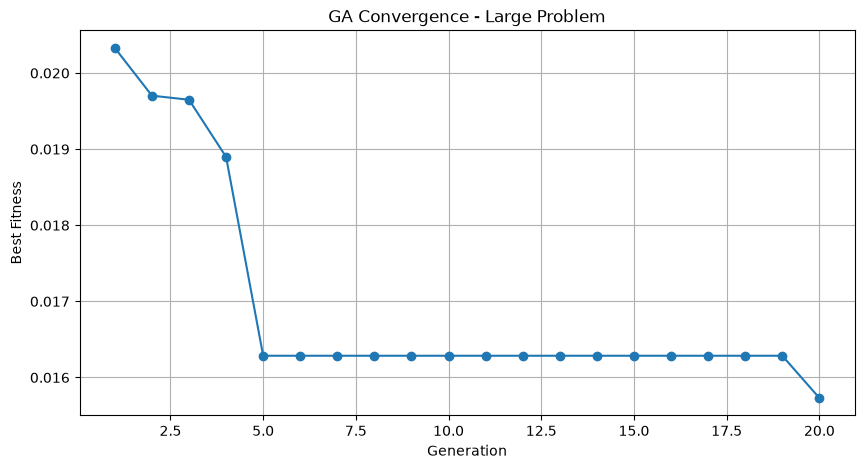

In [16]:
import matplotlib.pyplot as plt

ga_large_convergence = ga_large_result["Convergence"]

plt.figure(figsize=(10, 5))

plt.plot(
    ga_large_convergence["Generation"],
    ga_large_convergence["Best Fitness"],
    marker="o"
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("GA Convergence - Large Problem")
plt.grid(True)

plt.show()

# PSO

In [17]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


total_features = X_opt.shape[1]
lambda_penalty = 0.01


def evaluate_pso_solution(solution, max_features):
    selected_features = np.where(solution == 1)[0]
    number_selected = len(selected_features)

    if number_selected == 0:
        return float("inf"), 0, 0, 0

    if number_selected > max_features:
        return float("inf"), number_selected, 0, 0

    X_opt_selected = X_opt.iloc[:, selected_features]
    X_val_selected = X_val.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_opt_selected, y_opt)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions, average="macro")

    error = 1 - accuracy
    feature_ratio = number_selected / total_features

    fitness = error + lambda_penalty * feature_ratio

    return fitness, number_selected, accuracy, f1


def create_pso_particle(max_features):
    position = np.zeros(total_features, dtype=int)

    number_selected = np.random.randint(
        1,
        max_features + 1
    )

    selected_indices = np.random.choice(
        total_features,
        size=number_selected,
        replace=False
    )

    position[selected_indices] = 1

    velocity = np.random.uniform(
        -1,
        1,
        total_features
    )

    return position, velocity


def repair_pso_position(position, max_features):
    selected_indices = np.where(position == 1)[0]

    if len(selected_indices) > max_features:
        remove_count = len(selected_indices) - max_features

        remove_indices = np.random.choice(
            selected_indices,
            size=remove_count,
            replace=False
        )

        position[remove_indices] = 0

    if position.sum() == 0:
        random_index = np.random.randint(total_features)
        position[random_index] = 1

    return position


def run_particle_swarm_optimization(
    problem_name,
    max_features,
    swarm_size=20,
    iterations=20,
    inertia=0.7,
    cognitive=1.5,
    social=1.5,
    random_seed=42
):
    np.random.seed(random_seed)

    start_time = time.time()

    positions = []
    velocities = []

    for _ in range(swarm_size):
        position, velocity = create_pso_particle(
            max_features
        )

        positions.append(position)
        velocities.append(velocity)

    positions = np.array(positions)
    velocities = np.array(velocities)

    personal_best_positions = positions.copy()

    personal_best_fitness = np.full(
        swarm_size,
        float("inf")
    )

    global_best_position = None
    global_best_fitness = float("inf")
    global_best_accuracy = 0
    global_best_f1 = 0
    global_best_feature_count = 0

    convergence_history = []

    for iteration in range(iterations):

        for i in range(swarm_size):

            fitness, feature_count, accuracy, f1 = (
                evaluate_pso_solution(
                    positions[i],
                    max_features
                )
            )

            if fitness < personal_best_fitness[i]:
                personal_best_fitness[i] = fitness
                personal_best_positions[i] = positions[i].copy()

            if fitness < global_best_fitness:
                global_best_fitness = fitness
                global_best_position = positions[i].copy()
                global_best_accuracy = accuracy
                global_best_f1 = f1
                global_best_feature_count = feature_count

        convergence_history.append({
            "Iteration": iteration + 1,
            "Best Fitness": global_best_fitness,
            "Best Accuracy": global_best_accuracy,
            "Best Macro-F1": global_best_f1,
            "Selected Features": global_best_feature_count
        })

        print(
            f"Iteration {iteration + 1}/{iterations} | "
            f"Fitness: {global_best_fitness:.6f} | "
            f"Features: {global_best_feature_count} | "
            f"Accuracy: {global_best_accuracy:.4f}"
        )

        for i in range(swarm_size):

            r1 = np.random.rand(total_features)
            r2 = np.random.rand(total_features)

            velocities[i] = (
                inertia * velocities[i]
                + cognitive * r1
                * (
                    personal_best_positions[i]
                    - positions[i]
                )
                + social * r2
                * (
                    global_best_position
                    - positions[i]
                )
            )

            sigmoid = 1 / (
                1 + np.exp(
                    -np.clip(
                        velocities[i],
                        -20,
                        20
                    )
                )
            )

            random_values = np.random.rand(
                total_features
            )

            positions[i] = (
                random_values < sigmoid
            ).astype(int)

            positions[i] = repair_pso_position(
                positions[i],
                max_features
            )

    runtime = time.time() - start_time

    return {
        "Algorithm": "PSO",
        "Problem Size": problem_name,
        "Max Features": max_features,
        "Best Fitness": global_best_fitness,
        "Selected Features": global_best_feature_count,
        "Validation Accuracy": global_best_accuracy,
        "Validation Macro-F1": global_best_f1,
        "Runtime (seconds)": runtime,
        "Best Solution": global_best_position,
        "Convergence": pd.DataFrame(convergence_history)
    }

In [18]:
pso_small_result = run_particle_swarm_optimization(
    problem_name="Small",
    max_features=100,
    swarm_size=20,
    iterations=20,
    inertia=0.7,
    cognitive=1.5,
    social=1.5,
    random_seed=42
)

Iteration 1/20 | Fitness: 0.022696 | Features: 91 | Accuracy: 0.9789
Iteration 2/20 | Fitness: 0.019458 | Features: 100 | Accuracy: 0.9823
Iteration 3/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 4/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 5/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 6/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 7/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 8/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 9/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 10/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 11/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 12/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 13/20 | Fitness: 0.018098 | Features: 100 | Accuracy: 0.9837
Iteration 14/20 | Fitness: 0.016059 | Features: 100 | Accuracy: 0.9857
Iteration 15/20 

In [19]:
pso_medium_result = run_particle_swarm_optimization(
    problem_name="Medium",
    max_features=300,
    swarm_size=20,
    iterations=20,
    inertia=0.7,
    cognitive=1.5,
    social=1.5,
    random_seed=42
)

Iteration 1/20 | Fitness: 0.021879 | Features: 274 | Accuracy: 0.9830
Iteration 2/20 | Fitness: 0.020680 | Features: 283 | Accuracy: 0.9844
Iteration 3/20 | Fitness: 0.020680 | Features: 283 | Accuracy: 0.9844
Iteration 4/20 | Fitness: 0.020235 | Features: 258 | Accuracy: 0.9844
Iteration 5/20 | Fitness: 0.020235 | Features: 258 | Accuracy: 0.9844
Iteration 6/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 7/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 8/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 9/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 10/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 11/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 12/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 13/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 14/20 | Fitness: 0.018409 | Features: 270 | Accuracy: 0.9864
Iteration 15/20

In [20]:
pso_large_result = run_particle_swarm_optimization(
    problem_name="Large",
    max_features=561,
    swarm_size=20,
    iterations=20,
    inertia=0.7,
    cognitive=1.5,
    social=1.5,
    random_seed=42
)

Iteration 1/20 | Fitness: 0.022635 | Features: 202 | Accuracy: 0.9810
Iteration 2/20 | Fitness: 0.020968 | Features: 261 | Accuracy: 0.9837
Iteration 3/20 | Fitness: 0.020968 | Features: 261 | Accuracy: 0.9837
Iteration 4/20 | Fitness: 0.020968 | Features: 261 | Accuracy: 0.9837
Iteration 5/20 | Fitness: 0.020968 | Features: 261 | Accuracy: 0.9837
Iteration 6/20 | Fitness: 0.020968 | Features: 261 | Accuracy: 0.9837
Iteration 7/20 | Fitness: 0.020968 | Features: 261 | Accuracy: 0.9837
Iteration 8/20 | Fitness: 0.020968 | Features: 261 | Accuracy: 0.9837
Iteration 9/20 | Fitness: 0.019555 | Features: 258 | Accuracy: 0.9850
Iteration 10/20 | Fitness: 0.019555 | Features: 258 | Accuracy: 0.9850
Iteration 11/20 | Fitness: 0.019000 | Features: 265 | Accuracy: 0.9857
Iteration 12/20 | Fitness: 0.019000 | Features: 265 | Accuracy: 0.9857
Iteration 13/20 | Fitness: 0.019000 | Features: 265 | Accuracy: 0.9857
Iteration 14/20 | Fitness: 0.018498 | Features: 275 | Accuracy: 0.9864
Iteration 15/20

In [21]:
pso_summary = pd.DataFrame([
    {
        "Problem Size": pso_small_result["Problem Size"],
        "Max Features": pso_small_result["Max Features"],
        "Selected Features": pso_small_result["Selected Features"],
        "Best Fitness": pso_small_result["Best Fitness"],
        "Validation Accuracy": pso_small_result["Validation Accuracy"],
        "Validation Macro-F1": pso_small_result["Validation Macro-F1"],
        "Runtime (seconds)": pso_small_result["Runtime (seconds)"]
    },
    {
        "Problem Size": pso_medium_result["Problem Size"],
        "Max Features": pso_medium_result["Max Features"],
        "Selected Features": pso_medium_result["Selected Features"],
        "Best Fitness": pso_medium_result["Best Fitness"],
        "Validation Accuracy": pso_medium_result["Validation Accuracy"],
        "Validation Macro-F1": pso_medium_result["Validation Macro-F1"],
        "Runtime (seconds)": pso_medium_result["Runtime (seconds)"]
    },
    {
        "Problem Size": pso_large_result["Problem Size"],
        "Max Features": pso_large_result["Max Features"],
        "Selected Features": pso_large_result["Selected Features"],
        "Best Fitness": pso_large_result["Best Fitness"],
        "Validation Accuracy": pso_large_result["Validation Accuracy"],
        "Validation Macro-F1": pso_large_result["Validation Macro-F1"],
        "Runtime (seconds)": pso_large_result["Runtime (seconds)"]
    }
])

display(pso_summary)

,Problem Size,Max Features,Selected Features,Best Fitness,Validation Accuracy,Validation Macro-F1,Runtime (seconds)
0,Small,100,100,0.015379,0.986404,0.986762,794.137001
1,Medium,300,270,0.018409,0.986404,0.986709,1162.841472
2,Large,561,275,0.018498,0.986404,0.986501,926.829519


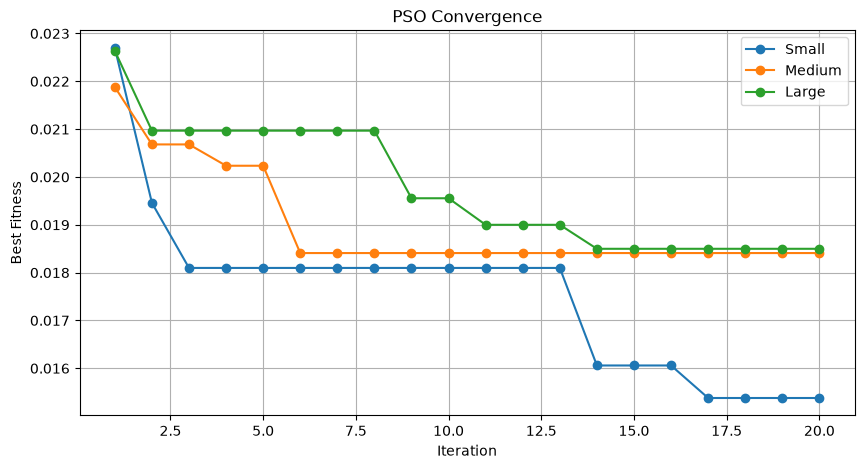

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    pso_small_result["Convergence"]["Iteration"],
    pso_small_result["Convergence"]["Best Fitness"],
    marker="o",
    label="Small"
)

plt.plot(
    pso_medium_result["Convergence"]["Iteration"],
    pso_medium_result["Convergence"]["Best Fitness"],
    marker="o",
    label="Medium"
)

plt.plot(
    pso_large_result["Convergence"]["Iteration"],
    pso_large_result["Convergence"]["Best Fitness"],
    marker="o",
    label="Large"
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence")
plt.legend()
plt.grid(True)

plt.show()

# ACO

In [23]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


total_features = X_opt.shape[1]
lambda_penalty = 0.01


def evaluate_aco_solution(solution, max_features):
    selected_features = np.where(solution == 1)[0]
    number_selected = len(selected_features)

    if number_selected == 0:
        return float("inf"), 0, 0, 0

    if number_selected > max_features:
        return float("inf"), number_selected, 0, 0

    X_opt_selected = X_opt.iloc[:, selected_features]
    X_val_selected = X_val.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_opt_selected, y_opt)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions, average="macro")

    error = 1 - accuracy
    feature_ratio = number_selected / total_features

    fitness = error + lambda_penalty * feature_ratio

    return fitness, number_selected, accuracy, f1


def create_aco_solution(
    pheromone,
    max_features,
    alpha=1.0
):
    probabilities = (
        pheromone ** alpha
    )

    probabilities = probabilities / probabilities.sum()

    number_selected = np.random.randint(
        1,
        max_features + 1
    )

    selected_indices = np.random.choice(
        total_features,
        size=number_selected,
        replace=False,
        p=probabilities
    )

    solution = np.zeros(
        total_features,
        dtype=int
    )

    solution[selected_indices] = 1

    return solution


def repair_aco_solution(
    solution,
    max_features,
    pheromone
):
    selected_indices = np.where(solution == 1)[0]

    if len(selected_indices) > max_features:

        remove_count = (
            len(selected_indices) - max_features
        )

        remove_probabilities = (
            pheromone[selected_indices]
        )

        remove_probabilities = (
            remove_probabilities
            / remove_probabilities.sum()
        )

        remove_indices = np.random.choice(
            selected_indices,
            size=remove_count,
            replace=False,
            p=remove_probabilities
        )

        solution[remove_indices] = 0

    if solution.sum() == 0:
        solution[
            np.random.randint(total_features)
        ] = 1

    return solution


def run_ant_colony_optimization(
    problem_name,
    max_features,
    number_ants=20,
    iterations=20,
    evaporation_rate=0.5,
    pheromone_weight=1.0,
    pheromone_deposit=1.0,
    random_seed=42
):
    np.random.seed(random_seed)

    start_time = time.time()

    pheromone = np.ones(
        total_features
    )

    best_solution = None
    best_fitness = float("inf")
    best_accuracy = 0
    best_f1 = 0
    best_feature_count = 0

    convergence_history = []

    for iteration in range(iterations):

        ant_solutions = []
        ant_fitnesses = []
        ant_feature_counts = []
        ant_accuracies = []
        ant_f1_scores = []

        for ant in range(number_ants):

            solution = create_aco_solution(
                pheromone,
                max_features,
                alpha=pheromone_weight
            )

            solution = repair_aco_solution(
                solution,
                max_features,
                pheromone
            )

            fitness, feature_count, accuracy, f1 = (
                evaluate_aco_solution(
                    solution,
                    max_features
                )
            )

            ant_solutions.append(solution)
            ant_fitnesses.append(fitness)
            ant_feature_counts.append(feature_count)
            ant_accuracies.append(accuracy)
            ant_f1_scores.append(f1)

            if fitness < best_fitness:

                best_fitness = fitness
                best_solution = solution.copy()
                best_accuracy = accuracy
                best_f1 = f1
                best_feature_count = feature_count

        pheromone *= (
            1 - evaporation_rate
        )

        for ant in range(number_ants):

            solution = ant_solutions[ant]
            fitness = ant_fitnesses[ant]

            if np.isfinite(fitness):

                deposit = (
                    pheromone_deposit
                    / (fitness + 1e-10)
                )

                selected_indices = np.where(
                    solution == 1
                )[0]

                pheromone[selected_indices] += deposit

        convergence_history.append({
            "Iteration": iteration + 1,
            "Best Fitness": best_fitness,
            "Best Accuracy": best_accuracy,
            "Best Macro-F1": best_f1,
            "Selected Features": best_feature_count
        })

        print(
            f"Iteration {iteration + 1}/{iterations} | "
            f"Fitness: {best_fitness:.6f} | "
            f"Features: {best_feature_count} | "
            f"Accuracy: {best_accuracy:.4f}"
        )

    runtime = time.time() - start_time

    return {
        "Algorithm": "ACO",
        "Problem Size": problem_name,
        "Max Features": max_features,
        "Best Fitness": best_fitness,
        "Selected Features": best_feature_count,
        "Validation Accuracy": best_accuracy,
        "Validation Macro-F1": best_f1,
        "Runtime (seconds)": runtime,
        "Best Solution": best_solution,
        "Convergence": pd.DataFrame(
            convergence_history
        )
    }

In [24]:
aco_small_result = run_ant_colony_optimization(
    problem_name="Small",
    max_features=100,
    number_ants=20,
    iterations=20,
    evaporation_rate=0.5,
    pheromone_weight=1.0,
    pheromone_deposit=1.0,
    random_seed=42
)

Iteration 1/20 | Fitness: 0.026077 | Features: 90 | Accuracy: 0.9755
Iteration 2/20 | Fitness: 0.022538 | Features: 44 | Accuracy: 0.9782
Iteration 3/20 | Fitness: 0.022538 | Features: 44 | Accuracy: 0.9782
Iteration 4/20 | Fitness: 0.021230 | Features: 85 | Accuracy: 0.9803
Iteration 5/20 | Fitness: 0.018706 | Features: 96 | Accuracy: 0.9830
Iteration 6/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 7/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 8/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 9/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 10/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 11/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 12/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 13/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 14/20 | Fitness: 0.017813 | Features: 84 | Accuracy: 0.9837
Iteration 15/20 | Fitness: 0.

In [25]:
aco_medium_result = run_ant_colony_optimization(
    problem_name="Medium",
    max_features=300,
    number_ants=20,
    iterations=20,
    evaporation_rate=0.5,
    pheromone_weight=1.0,
    pheromone_deposit=1.0,
    random_seed=42
)

Iteration 1/20 | Fitness: 0.022230 | Features: 103 | Accuracy: 0.9796
Iteration 2/20 | Fitness: 0.021426 | Features: 96 | Accuracy: 0.9803
Iteration 3/20 | Fitness: 0.020137 | Features: 100 | Accuracy: 0.9816
Iteration 4/20 | Fitness: 0.020137 | Features: 100 | Accuracy: 0.9816
Iteration 5/20 | Fitness: 0.020046 | Features: 133 | Accuracy: 0.9823
Iteration 6/20 | Fitness: 0.020046 | Features: 133 | Accuracy: 0.9823
Iteration 7/20 | Fitness: 0.020046 | Features: 133 | Accuracy: 0.9823
Iteration 8/20 | Fitness: 0.020046 | Features: 133 | Accuracy: 0.9823
Iteration 9/20 | Fitness: 0.020046 | Features: 133 | Accuracy: 0.9823
Iteration 10/20 | Fitness: 0.019600 | Features: 108 | Accuracy: 0.9823
Iteration 11/20 | Fitness: 0.019600 | Features: 108 | Accuracy: 0.9823
Iteration 12/20 | Fitness: 0.019333 | Features: 93 | Accuracy: 0.9823
Iteration 13/20 | Fitness: 0.019333 | Features: 93 | Accuracy: 0.9823
Iteration 14/20 | Fitness: 0.019333 | Features: 93 | Accuracy: 0.9823
Iteration 15/20 | F

In [26]:
aco_large_result = run_ant_colony_optimization(
    problem_name="Large",
    max_features=561,
    number_ants=20,
    iterations=20,
    evaporation_rate=0.5,
    pheromone_weight=1.0,
    pheromone_deposit=1.0,
    random_seed=42
)

Iteration 1/20 | Fitness: 0.021879 | Features: 274 | Accuracy: 0.9830
Iteration 2/20 | Fitness: 0.020649 | Features: 205 | Accuracy: 0.9830
Iteration 3/20 | Fitness: 0.020649 | Features: 205 | Accuracy: 0.9830
Iteration 4/20 | Fitness: 0.020649 | Features: 205 | Accuracy: 0.9830
Iteration 5/20 | Fitness: 0.020649 | Features: 205 | Accuracy: 0.9830
Iteration 6/20 | Fitness: 0.020649 | Features: 205 | Accuracy: 0.9830
Iteration 7/20 | Fitness: 0.020649 | Features: 205 | Accuracy: 0.9830
Iteration 8/20 | Fitness: 0.019651 | Features: 149 | Accuracy: 0.9830
Iteration 9/20 | Fitness: 0.019651 | Features: 149 | Accuracy: 0.9830
Iteration 10/20 | Fitness: 0.018989 | Features: 150 | Accuracy: 0.9837
Iteration 11/20 | Fitness: 0.018989 | Features: 150 | Accuracy: 0.9837
Iteration 12/20 | Fitness: 0.018989 | Features: 150 | Accuracy: 0.9837
Iteration 13/20 | Fitness: 0.018989 | Features: 150 | Accuracy: 0.9837
Iteration 14/20 | Fitness: 0.018989 | Features: 150 | Accuracy: 0.9837
Iteration 15/20

In [27]:
aco_summary = pd.DataFrame([
    {
        "Problem Size": aco_small_result["Problem Size"],
        "Max Features": aco_small_result["Max Features"],
        "Selected Features": aco_small_result["Selected Features"],
        "Best Fitness": aco_small_result["Best Fitness"],
        "Validation Accuracy": aco_small_result["Validation Accuracy"],
        "Validation Macro-F1": aco_small_result["Validation Macro-F1"],
        "Runtime (seconds)": aco_small_result["Runtime (seconds)"]
    },
    {
        "Problem Size": aco_medium_result["Problem Size"],
        "Max Features": aco_medium_result["Max Features"],
        "Selected Features": aco_medium_result["Selected Features"],
        "Best Fitness": aco_medium_result["Best Fitness"],
        "Validation Accuracy": aco_medium_result["Validation Accuracy"],
        "Validation Macro-F1": aco_medium_result["Validation Macro-F1"],
        "Runtime (seconds)": aco_medium_result["Runtime (seconds)"]
    },
    {
        "Problem Size": aco_large_result["Problem Size"],
        "Max Features": aco_large_result["Max Features"],
        "Selected Features": aco_large_result["Selected Features"],
        "Best Fitness": aco_large_result["Best Fitness"],
        "Validation Accuracy": aco_large_result["Validation Accuracy"],
        "Validation Macro-F1": aco_large_result["Validation Macro-F1"],
        "Runtime (seconds)": aco_large_result["Runtime (seconds)"]
    }
])

display(aco_summary)

,Problem Size,Max Features,Selected Features,Best Fitness,Validation Accuracy,Validation Macro-F1,Runtime (seconds)
0,Small,100,84,0.017813,0.983685,0.983672,426.455472
1,Medium,300,125,0.017184,0.985044,0.985431,666.388901
2,Large,561,150,0.018989,0.983685,0.983886,860.072446


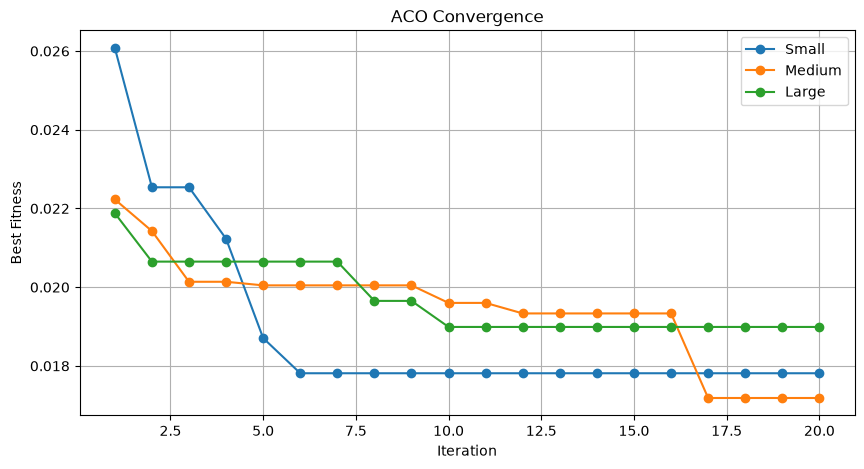

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    aco_small_result["Convergence"]["Iteration"],
    aco_small_result["Convergence"]["Best Fitness"],
    marker="o",
    label="Small"
)

plt.plot(
    aco_medium_result["Convergence"]["Iteration"],
    aco_medium_result["Convergence"]["Best Fitness"],
    marker="o",
    label="Medium"
)

plt.plot(
    aco_large_result["Convergence"]["Iteration"],
    aco_large_result["Convergence"]["Best Fitness"],
    marker="o",
    label="Large"
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("ACO Convergence")
plt.legend()
plt.grid(True)

plt.show()

# Comparsion

In [29]:
comparison_df = pd.concat(
    [
        ga_summary.assign(Algorithm="GA"),
        pso_summary.assign(Algorithm="PSO"),
        aco_summary.assign(Algorithm="ACO")
    ],
    ignore_index=True
)

comparison_df = comparison_df[
    [
        "Problem Size",
        "Algorithm",
        "Max Features",
        "Selected Features",
        "Best Fitness",
        "Validation Accuracy",
        "Validation Macro-F1",
        "Runtime (seconds)"
    ]
]

comparison_df = comparison_df.sort_values(
    ["Problem Size", "Algorithm"]
).reset_index(drop=True)

display(comparison_df)

,Problem Size,Algorithm,Max Features,Selected Features,Best Fitness,Validation Accuracy,Validation Macro-F1,Runtime (seconds)
0,Large,ACO,561,150,0.018989,0.983685,0.983886,860.072446
1,Large,GA,561,196,0.015730,0.987763,0.988248,1031.399787
2,Large,PSO,561,275,0.018498,0.986404,0.986501,926.829519
3,Medium,ACO,300,125,0.017184,0.985044,0.985431,666.388901
4,Medium,GA,300,147,0.014857,0.987763,0.987894,905.579213
5,Medium,PSO,300,270,0.018409,0.986404,0.986709,1162.841472
6,Small,ACO,100,84,0.017813,0.983685,0.983672,426.455472
7,Small,GA,100,100,0.014699,0.987084,0.987337,760.803566
8,Small,PSO,100,100,0.015379,0.986404,0.986762,794.137001


In [30]:
comparison_df["Feature Reduction (%)"] = (
    (561 - comparison_df["Selected Features"]) / 561
) * 100

display(comparison_df)

,Problem Size,Algorithm,Max Features,Selected Features,Best Fitness,Validation Accuracy,Validation Macro-F1,Runtime (seconds),Feature Reduction (%)
0,Large,ACO,561,150,0.018989,0.983685,0.983886,860.072446,73.262032
1,Large,GA,561,196,0.015730,0.987763,0.988248,1031.399787,65.062389
2,Large,PSO,561,275,0.018498,0.986404,0.986501,926.829519,50.980392
3,Medium,ACO,300,125,0.017184,0.985044,0.985431,666.388901,77.718360
4,Medium,GA,300,147,0.014857,0.987763,0.987894,905.579213,73.796791
5,Medium,PSO,300,270,0.018409,0.986404,0.986709,1162.841472,51.871658
6,Small,ACO,100,84,0.017813,0.983685,0.983672,426.455472,85.026738
7,Small,GA,100,100,0.014699,0.987084,0.987337,760.803566,82.174688
8,Small,PSO,100,100,0.015379,0.986404,0.986762,794.137001,82.174688


In [31]:
formatted_comparison = comparison_df.copy()

formatted_comparison["Best Fitness"] = (
    formatted_comparison["Best Fitness"].round(6)
)

formatted_comparison["Validation Accuracy (%)"] = (
    formatted_comparison["Validation Accuracy"] * 100
).round(2)

formatted_comparison["Validation Macro-F1 (%)"] = (
    formatted_comparison["Validation Macro-F1"] * 100
).round(2)

formatted_comparison["Runtime (seconds)"] = (
    formatted_comparison["Runtime (seconds)"].round(2)
)

formatted_comparison["Feature Reduction (%)"] = (
    formatted_comparison["Feature Reduction (%)"].round(2)
)

formatted_comparison = formatted_comparison[
    [
        "Problem Size",
        "Algorithm",
        "Max Features",
        "Selected Features",
        "Feature Reduction (%)",
        "Best Fitness",
        "Validation Accuracy (%)",
        "Validation Macro-F1 (%)",
        "Runtime (seconds)"
    ]
]

display(formatted_comparison)

,Problem Size,Algorithm,Max Features,Selected Features,Feature Reduction (%),Best Fitness,Validation Accuracy (%),Validation Macro-F1 (%),Runtime (seconds)
0,Large,ACO,561,150,73.26,0.018989,98.37,98.39,860.07
1,Large,GA,561,196,65.06,0.015730,98.78,98.82,1031.40
2,Large,PSO,561,275,50.98,0.018498,98.64,98.65,926.83
3,Medium,ACO,300,125,77.72,0.017184,98.50,98.54,666.39
4,Medium,GA,300,147,73.80,0.014857,98.78,98.79,905.58
5,Medium,PSO,300,270,51.87,0.018409,98.64,98.67,1162.84
6,Small,ACO,100,84,85.03,0.017813,98.37,98.37,426.46
7,Small,GA,100,100,82.17,0.014699,98.71,98.73,760.80
8,Small,PSO,100,100,82.17,0.015379,98.64,98.68,794.14


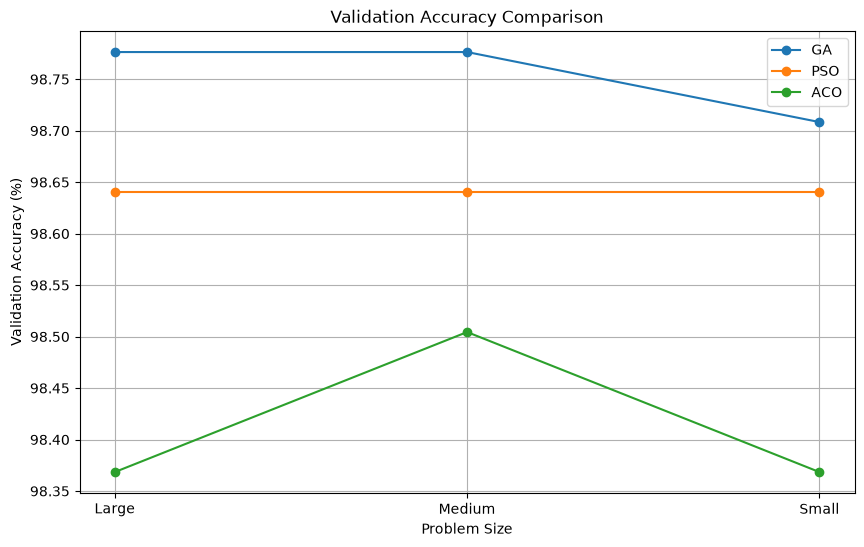

In [32]:
import matplotlib.pyplot as plt

accuracy_plot = comparison_df.copy()

accuracy_plot["Accuracy (%)"] = (
    accuracy_plot["Validation Accuracy"] * 100
)

plt.figure(figsize=(10, 6))

for algorithm in ["GA", "PSO", "ACO"]:
    data = accuracy_plot[
        accuracy_plot["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Problem Size"],
        data["Accuracy (%)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Problem Size")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.show()

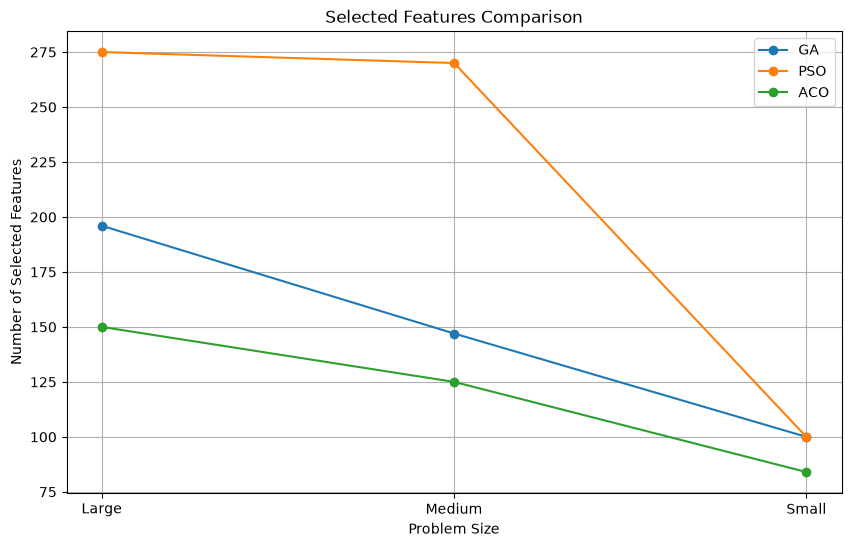

In [33]:
plt.figure(figsize=(10, 6))

for algorithm in ["GA", "PSO", "ACO"]:
    data = comparison_df[
        comparison_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Problem Size"],
        data["Selected Features"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Problem Size")
plt.ylabel("Number of Selected Features")
plt.title("Selected Features Comparison")
plt.legend()
plt.grid(True)
plt.show()

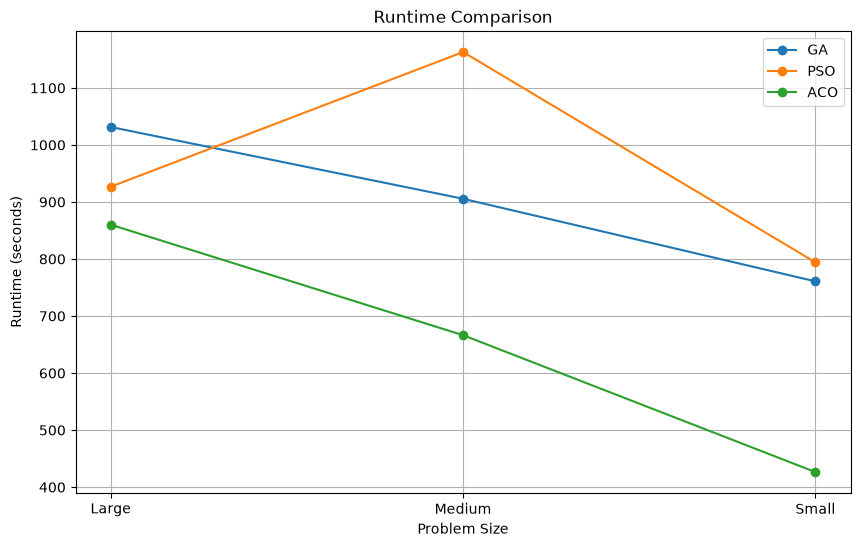

In [34]:
plt.figure(figsize=(10, 6))

for algorithm in ["GA", "PSO", "ACO"]:
    data = comparison_df[
        comparison_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Problem Size"],
        data["Runtime (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Problem Size")
plt.ylabel("Runtime (seconds)")
plt.title("Runtime Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [35]:
import time
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


def evaluate_final_solution(
    algorithm,
    problem_size,
    solution,
    n_estimators=100,
    random_state=42
):
    selected_features = np.where(solution == 1)[0]

    X_train_selected = X_train.iloc[:, selected_features]
    X_test_selected = X_test.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        random_state=random_state,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        X_train_selected,
        y_train["activity_id"]
    )

    training_time = time.time() - start_time

    start_time = time.time()

    predictions = model.predict(
        X_test_selected
    )

    prediction_time = time.time() - start_time

    accuracy = accuracy_score(
        y_test["activity_id"],
        predictions
    )

    macro_f1 = f1_score(
        y_test["activity_id"],
        predictions,
        average="macro"
    )

    feature_count = len(selected_features)

    feature_reduction = (
        (X_train.shape[1] - feature_count)
        / X_train.shape[1]
    ) * 100

    return {
        "Algorithm": algorithm,
        "Problem Size": problem_size,
        "Selected Features": feature_count,
        "Feature Reduction (%)": feature_reduction,
        "Test Accuracy": accuracy,
        "Test Macro-F1": macro_f1,
        "Training Time (seconds)": training_time,
        "Prediction Time (seconds)": prediction_time
    }

In [36]:
all_features_solution = np.ones(
    X_train.shape[1],
    dtype=int
)

baseline_test_result = evaluate_final_solution(
    algorithm="Random Forest Baseline",
    problem_size="All Features",
    solution=all_features_solution
)

baseline_test_result

{'Algorithm': 'Random Forest Baseline',
 'Problem Size': 'All Features',
 'Selected Features': 561,
 'Feature Reduction (%)': 0.0,
 'Test Accuracy': 0.9256871394638616,
 'Test Macro-F1': 0.9241030907153487,
 'Training Time (seconds)': 3.9339706897735596,
 'Prediction Time (seconds)': 0.07503771781921387}

In [37]:
ga_final_results = []

ga_final_results.append(
    evaluate_final_solution(
        algorithm="GA",
        problem_size="Small",
        solution=ga_small_result["Best Solution"]
    )
)

ga_final_results.append(
    evaluate_final_solution(
        algorithm="GA",
        problem_size="Medium",
        solution=ga_medium_result["Best Solution"]
    )
)

ga_final_results.append(
    evaluate_final_solution(
        algorithm="GA",
        problem_size="Large",
        solution=ga_large_result["Best Solution"]
    )
)

ga_final_test_df = pd.DataFrame(
    ga_final_results
)

display(ga_final_test_df)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy,Test Macro-F1,Training Time (seconds),Prediction Time (seconds)
0,GA,Small,100,82.174688,0.908042,0.904742,1.778254,0.066184
1,GA,Medium,147,73.796791,0.931795,0.928749,2.508174,0.068381
2,GA,Large,196,65.062389,0.928402,0.925496,3.037497,0.086687


In [38]:
pso_final_results = []

pso_final_results.append(
    evaluate_final_solution(
        algorithm="PSO",
        problem_size="Small",
        solution=pso_small_result["Best Solution"]
    )
)

pso_final_results.append(
    evaluate_final_solution(
        algorithm="PSO",
        problem_size="Medium",
        solution=pso_medium_result["Best Solution"]
    )
)

pso_final_results.append(
    evaluate_final_solution(
        algorithm="PSO",
        problem_size="Large",
        solution=pso_large_result["Best Solution"]
    )
)

pso_final_test_df = pd.DataFrame(
    pso_final_results
)

display(pso_final_test_df)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy,Test Macro-F1,Training Time (seconds),Prediction Time (seconds)
0,PSO,Small,100,82.174688,0.918222,0.915164,1.739225,0.134151
1,PSO,Medium,270,51.871658,0.920258,0.918094,2.614620,0.096921
2,PSO,Large,275,50.980392,0.936546,0.933834,2.634566,0.068416


In [39]:
pso_final_results = []

pso_final_results.append(
    evaluate_final_solution(
        algorithm="PSO",
        problem_size="Small",
        solution=pso_small_result["Best Solution"]
    )
)

pso_final_results.append(
    evaluate_final_solution(
        algorithm="PSO",
        problem_size="Medium",
        solution=pso_medium_result["Best Solution"]
    )
)

pso_final_results.append(
    evaluate_final_solution(
        algorithm="PSO",
        problem_size="Large",
        solution=pso_large_result["Best Solution"]
    )
)

pso_final_test_df = pd.DataFrame(
    pso_final_results
)

display(pso_final_test_df)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy,Test Macro-F1,Training Time (seconds),Prediction Time (seconds)
0,PSO,Small,100,82.174688,0.918222,0.915164,1.686167,0.065883
1,PSO,Medium,270,51.871658,0.920258,0.918094,2.582211,0.070099
2,PSO,Large,275,50.980392,0.936546,0.933834,2.717871,0.117435


In [40]:
aco_final_results = []

aco_final_results.append(
    evaluate_final_solution(
        algorithm="ACO",
        problem_size="Small",
        solution=aco_small_result["Best Solution"]
    )
)

aco_final_results.append(
    evaluate_final_solution(
        algorithm="ACO",
        problem_size="Medium",
        solution=aco_medium_result["Best Solution"]
    )
)

aco_final_results.append(
    evaluate_final_solution(
        algorithm="ACO",
        problem_size="Large",
        solution=aco_large_result["Best Solution"]
    )
)

aco_final_test_df = pd.DataFrame(
    aco_final_results
)

display(aco_final_test_df)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy,Test Macro-F1,Training Time (seconds),Prediction Time (seconds)
0,ACO,Small,84,85.026738,0.870037,0.868688,1.457240,0.063544
1,ACO,Medium,125,77.718360,0.919579,0.916104,1.941399,0.068049
2,ACO,Large,150,73.262032,0.925348,0.923372,2.027076,0.069023


In [41]:
final_comparison = pd.concat(
    [
        pd.DataFrame([baseline_test_result]),
        ga_final_test_df,
        pso_final_test_df,
        aco_final_test_df
    ],
    ignore_index=True
)

final_comparison = final_comparison[
    [
        "Algorithm",
        "Problem Size",
        "Selected Features",
        "Feature Reduction (%)",
        "Test Accuracy",
        "Test Macro-F1",
        "Training Time (seconds)",
        "Prediction Time (seconds)"
    ]
]

display(final_comparison)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy,Test Macro-F1,Training Time (seconds),Prediction Time (seconds)
0,Random Forest Baseline,All Features,561,0.000000,0.925687,0.924103,3.933971,0.075038
1,GA,Small,100,82.174688,0.908042,0.904742,1.778254,0.066184
2,GA,Medium,147,73.796791,0.931795,0.928749,2.508174,0.068381
3,GA,Large,196,65.062389,0.928402,0.925496,3.037497,0.086687
4,PSO,Small,100,82.174688,0.918222,0.915164,1.686167,0.065883
5,PSO,Medium,270,51.871658,0.920258,0.918094,2.582211,0.070099
6,PSO,Large,275,50.980392,0.936546,0.933834,2.717871,0.117435
7,ACO,Small,84,85.026738,0.870037,0.868688,1.457240,0.063544
8,ACO,Medium,125,77.718360,0.919579,0.916104,1.941399,0.068049
9,ACO,Large,150,73.262032,0.925348,0.923372,2.027076,0.069023


In [42]:
final_comparison_display = final_comparison.copy()

final_comparison_display["Feature Reduction (%)"] = (
    final_comparison_display["Feature Reduction (%)"].round(2)
)

final_comparison_display["Test Accuracy (%)"] = (
    final_comparison_display["Test Accuracy"] * 100
).round(2)

final_comparison_display["Test Macro-F1 (%)"] = (
    final_comparison_display["Test Macro-F1"] * 100
).round(2)

final_comparison_display["Training Time (seconds)"] = (
    final_comparison_display["Training Time (seconds)"].round(2)
)

final_comparison_display["Prediction Time (seconds)"] = (
    final_comparison_display["Prediction Time (seconds)"].round(2)
)

final_comparison_display = final_comparison_display[
    [
        "Algorithm",
        "Problem Size",
        "Selected Features",
        "Feature Reduction (%)",
        "Test Accuracy (%)",
        "Test Macro-F1 (%)",
        "Training Time (seconds)",
        "Prediction Time (seconds)"
    ]
]

display(final_comparison_display)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy (%),Test Macro-F1 (%),Training Time (seconds),Prediction Time (seconds)
0,Random Forest Baseline,All Features,561,0.00,92.57,92.41,3.93,0.08
1,GA,Small,100,82.17,90.80,90.47,1.78,0.07
2,GA,Medium,147,73.80,93.18,92.87,2.51,0.07
3,GA,Large,196,65.06,92.84,92.55,3.04,0.09
4,PSO,Small,100,82.17,91.82,91.52,1.69,0.07
5,PSO,Medium,270,51.87,92.03,91.81,2.58,0.07
6,PSO,Large,275,50.98,93.65,93.38,2.72,0.12
7,ACO,Small,84,85.03,87.00,86.87,1.46,0.06
8,ACO,Medium,125,77.72,91.96,91.61,1.94,0.07
9,ACO,Large,150,73.26,92.53,92.34,2.03,0.07


In [43]:
import matplotlib.pyplot as plt

plot_df = final_comparison.copy()

plot_df["Label"] = (
    plot_df["Algorithm"] + " - " +
    plot_df["Problem Size"]
)

display(plot_df)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy,Test Macro-F1,Training Time (seconds),Prediction Time (seconds),Label
0,Random Forest Baseline,All Features,561,0.000000,0.925687,0.924103,3.933971,0.075038,Random Forest Baseline - All Features
1,GA,Small,100,82.174688,0.908042,0.904742,1.778254,0.066184,GA - Small
2,GA,Medium,147,73.796791,0.931795,0.928749,2.508174,0.068381,GA - Medium
3,GA,Large,196,65.062389,0.928402,0.925496,3.037497,0.086687,GA - Large
4,PSO,Small,100,82.174688,0.918222,0.915164,1.686167,0.065883,PSO - Small
5,PSO,Medium,270,51.871658,0.920258,0.918094,2.582211,0.070099,PSO - Medium
6,PSO,Large,275,50.980392,0.936546,0.933834,2.717871,0.117435,PSO - Large
7,ACO,Small,84,85.026738,0.870037,0.868688,1.457240,0.063544,ACO - Small
8,ACO,Medium,125,77.718360,0.919579,0.916104,1.941399,0.068049,ACO - Medium
9,ACO,Large,150,73.262032,0.925348,0.923372,2.027076,0.069023,ACO - Large


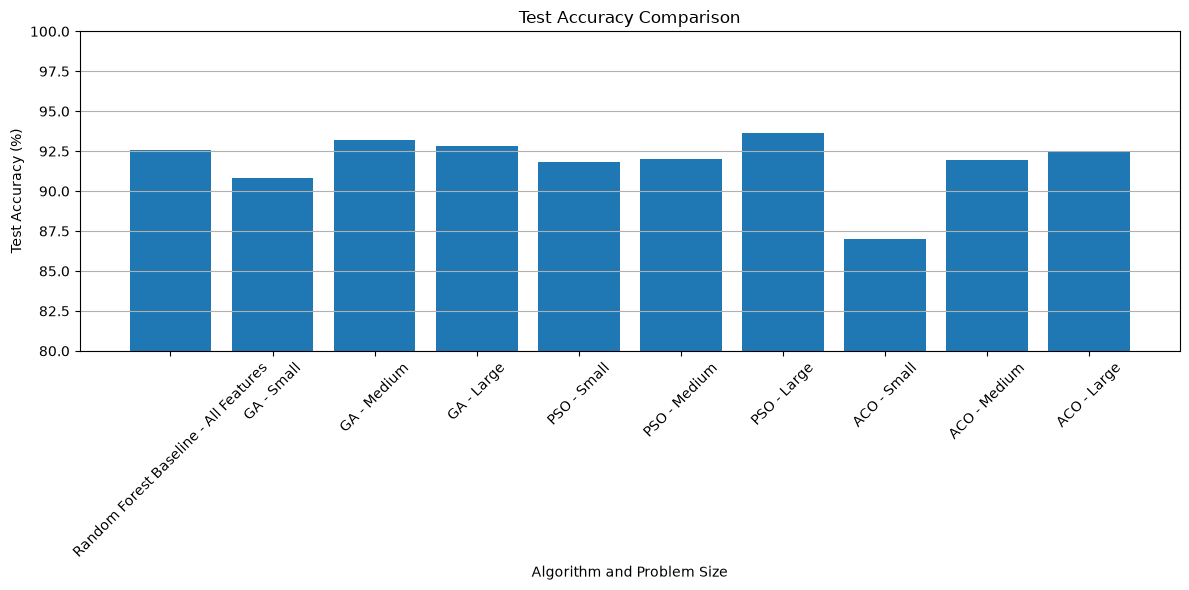

In [44]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Label"],
    plot_df["Test Accuracy"] * 100
)

plt.xlabel("Algorithm and Problem Size")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Comparison")
plt.xticks(rotation=45)
plt.ylim(80, 100)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

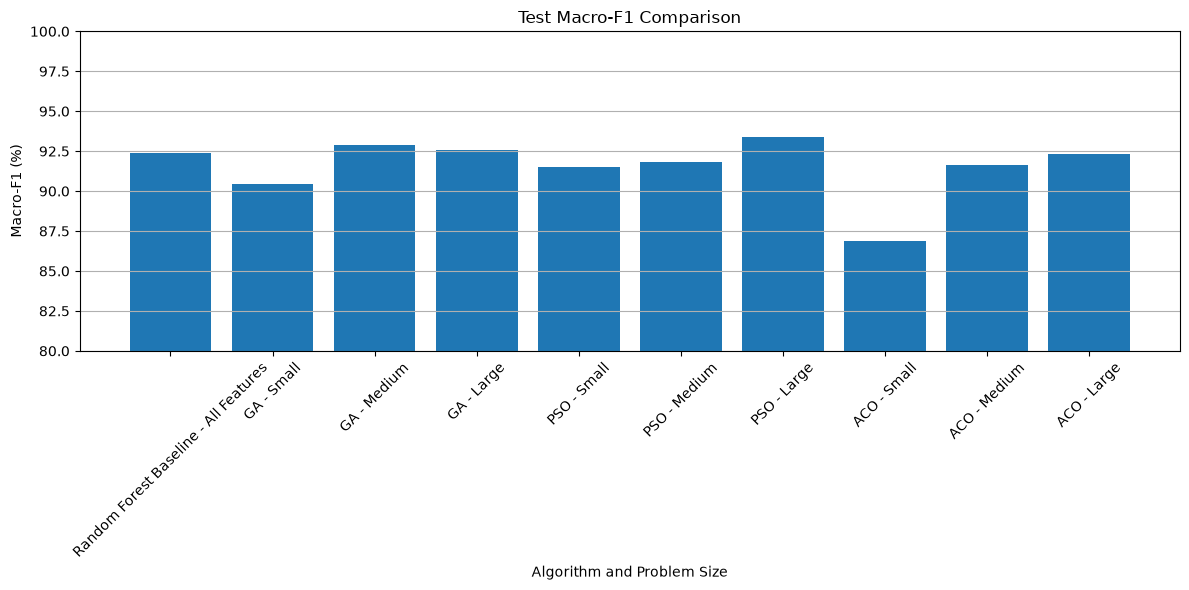

In [45]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Label"],
    plot_df["Test Macro-F1"] * 100
)

plt.xlabel("Algorithm and Problem Size")
plt.ylabel("Macro-F1 (%)")
plt.title("Test Macro-F1 Comparison")
plt.xticks(rotation=45)
plt.ylim(80, 100)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

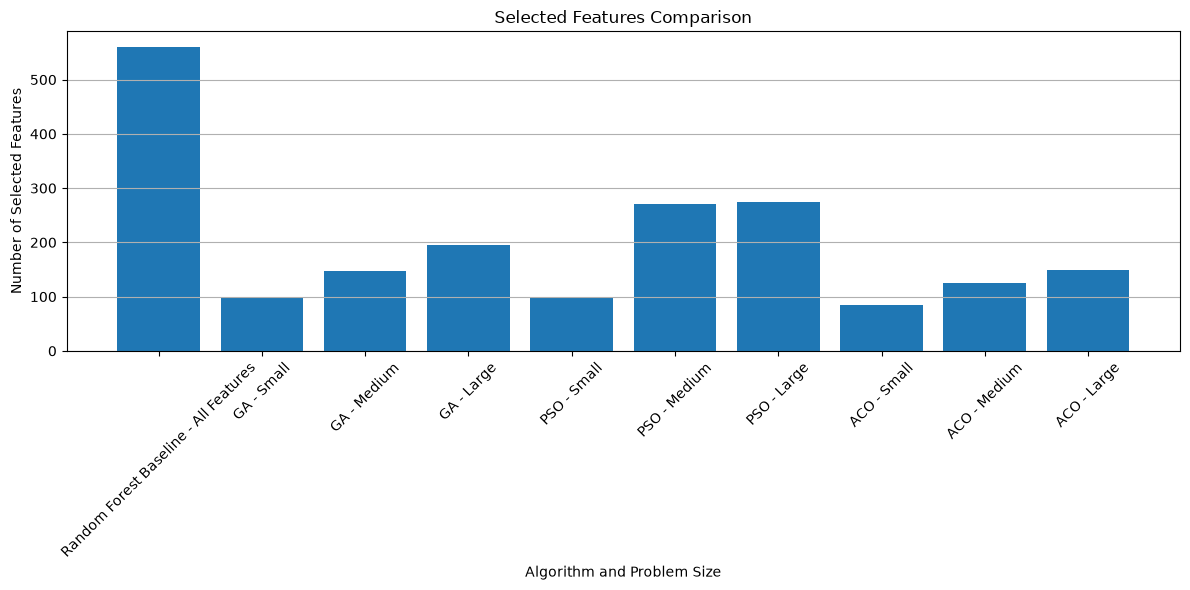

In [46]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Label"],
    plot_df["Selected Features"]
)

plt.xlabel("Algorithm and Problem Size")
plt.ylabel("Number of Selected Features")
plt.title("Selected Features Comparison")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

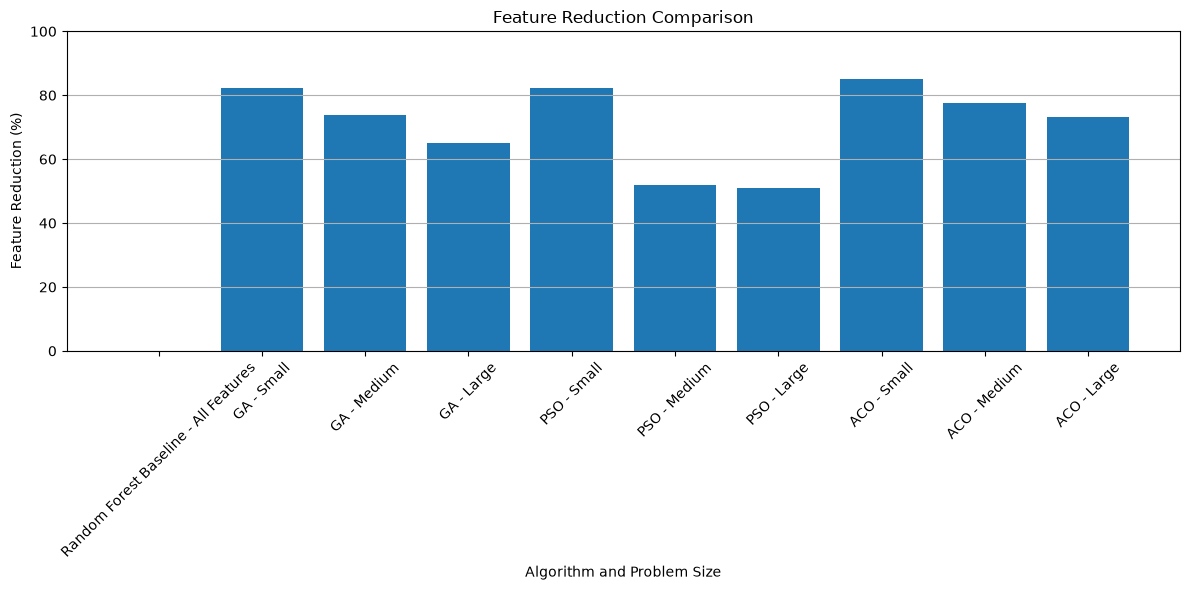

In [47]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Label"],
    plot_df["Feature Reduction (%)"]
)

plt.xlabel("Algorithm and Problem Size")
plt.ylabel("Feature Reduction (%)")
plt.title("Feature Reduction Comparison")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

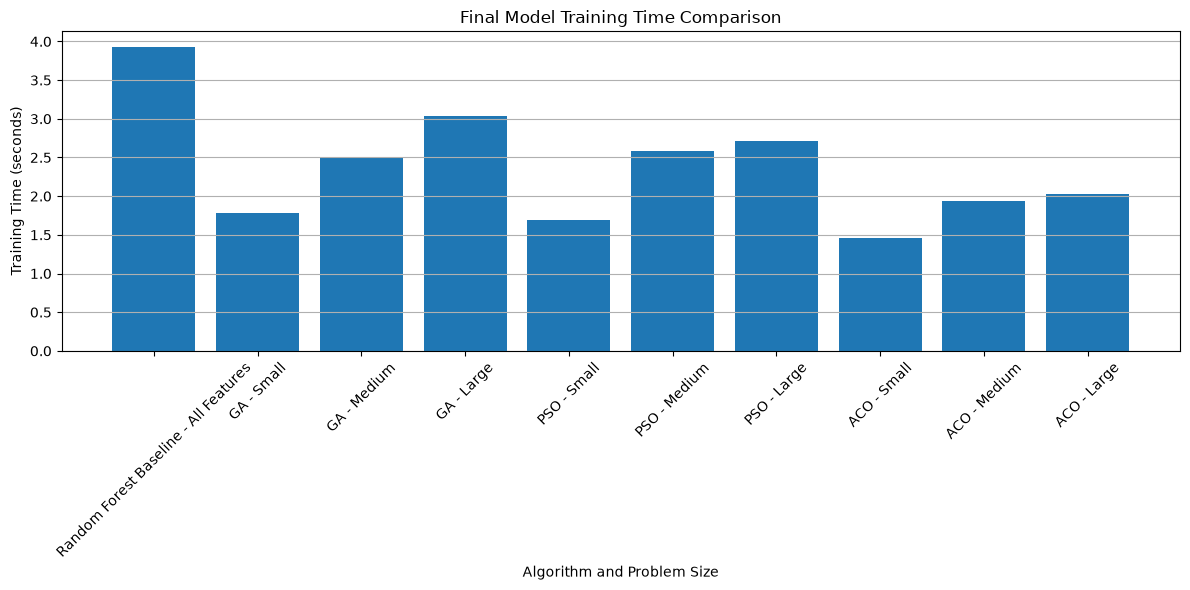

In [48]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Label"],
    plot_df["Training Time (seconds)"]
)

plt.xlabel("Algorithm and Problem Size")
plt.ylabel("Training Time (seconds)")
plt.title("Final Model Training Time Comparison")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

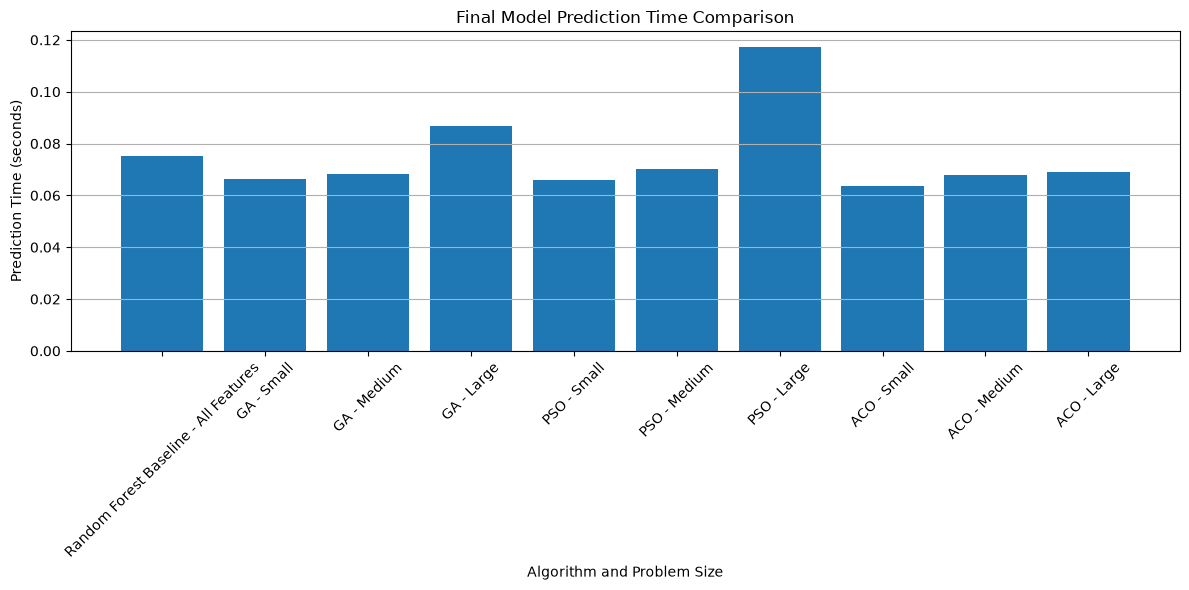

In [49]:
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Label"],
    plot_df["Prediction Time (seconds)"]
)

plt.xlabel("Algorithm and Problem Size")
plt.ylabel("Prediction Time (seconds)")
plt.title("Final Model Prediction Time Comparison")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

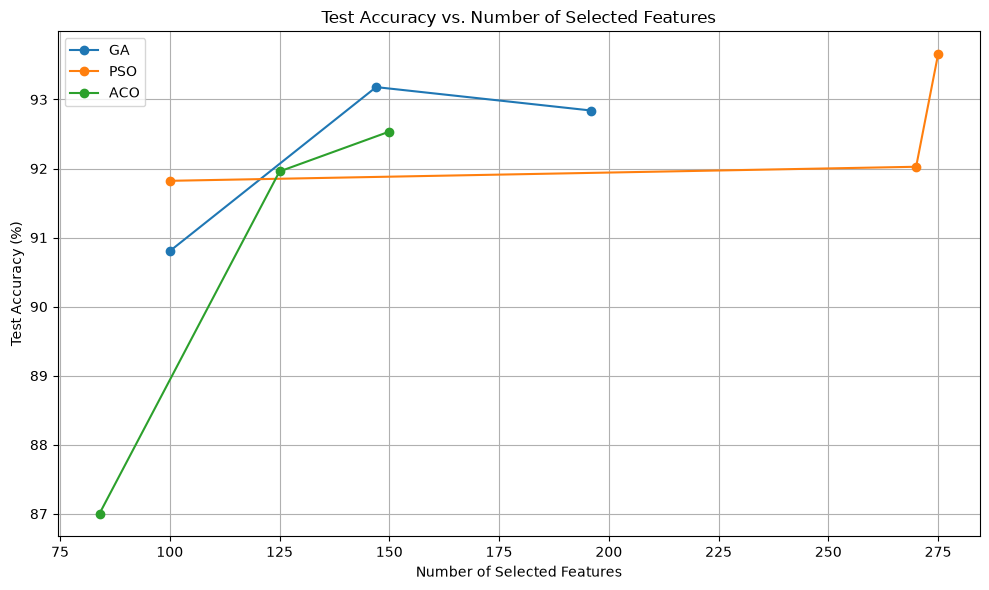

In [50]:
plt.figure(figsize=(10, 6))

for algorithm in ["GA", "PSO", "ACO"]:
    data = plot_df[
        plot_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Selected Features"],
        data["Test Accuracy"] * 100,
        marker="o",
        label=algorithm
    )

plt.xlabel("Number of Selected Features")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy vs. Number of Selected Features")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [51]:
final_results_display = final_comparison.copy()

final_results_display["Feature Reduction (%)"] = (
    final_results_display["Feature Reduction (%)"].round(2)
)

final_results_display["Test Accuracy (%)"] = (
    final_results_display["Test Accuracy"] * 100
).round(2)

final_results_display["Test Macro-F1 (%)"] = (
    final_results_display["Test Macro-F1"] * 100
).round(2)

final_results_display["Training Time (seconds)"] = (
    final_results_display["Training Time (seconds)"].round(2)
)

final_results_display["Prediction Time (seconds)"] = (
    final_results_display["Prediction Time (seconds)"].round(2)
)

final_results_display = final_results_display[
    [
        "Algorithm",
        "Problem Size",
        "Selected Features",
        "Feature Reduction (%)",
        "Test Accuracy (%)",
        "Test Macro-F1 (%)",
        "Training Time (seconds)",
        "Prediction Time (seconds)"
    ]
]

display(final_results_display)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy (%),Test Macro-F1 (%),Training Time (seconds),Prediction Time (seconds)
0,Random Forest Baseline,All Features,561,0.00,92.57,92.41,3.93,0.08
1,GA,Small,100,82.17,90.80,90.47,1.78,0.07
2,GA,Medium,147,73.80,93.18,92.87,2.51,0.07
3,GA,Large,196,65.06,92.84,92.55,3.04,0.09
4,PSO,Small,100,82.17,91.82,91.52,1.69,0.07
5,PSO,Medium,270,51.87,92.03,91.81,2.58,0.07
6,PSO,Large,275,50.98,93.65,93.38,2.72,0.12
7,ACO,Small,84,85.03,87.00,86.87,1.46,0.06
8,ACO,Medium,125,77.72,91.96,91.61,1.94,0.07
9,ACO,Large,150,73.26,92.53,92.34,2.03,0.07


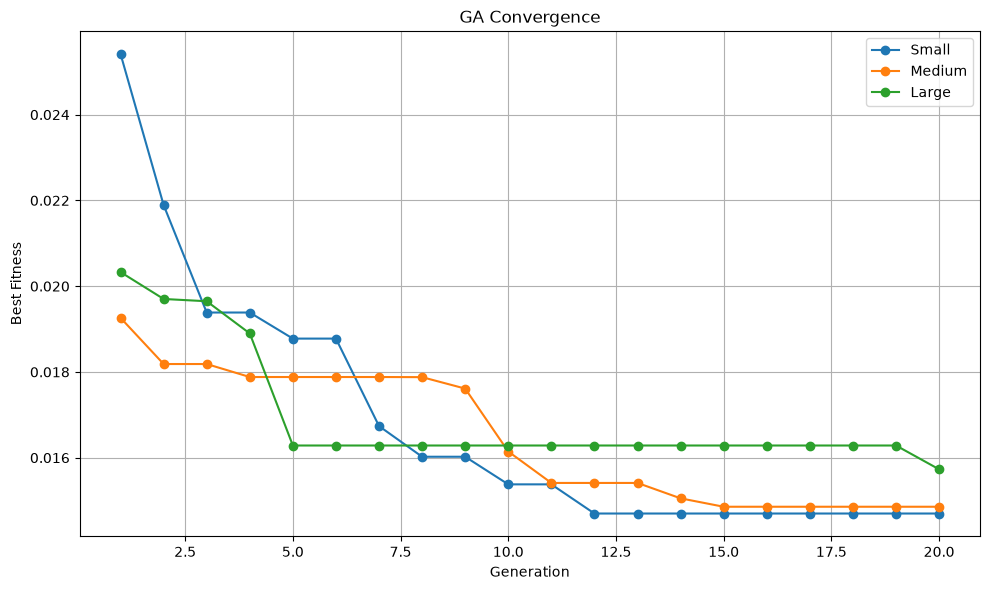

In [52]:
import matplotlib.pyplot as plt

ga_small = [
    0.025415, 0.021892, 0.019386, 0.019386, 0.018778,
    0.018778, 0.016738, 0.016023, 0.016023, 0.015379,
    0.015379, 0.014699, 0.014699, 0.014699, 0.014699,
    0.014699, 0.014699, 0.014699, 0.014699, 0.014699
]

ga_medium = [
    0.019262, 0.018185, 0.018185, 0.017882, 0.017882,
    0.017882, 0.017882, 0.017879, 0.017612, 0.016145,
    0.015412, 0.015412, 0.015412, 0.015053, 0.014857,
    0.014857, 0.014857, 0.014857, 0.014857, 0.014857
]

ga_large = [
    0.020329, 0.019702, 0.019649, 0.018898, 0.016285,
    0.016285, 0.016285, 0.016285, 0.016285, 0.016285,
    0.016285, 0.016285, 0.016285, 0.016285, 0.016285,
    0.016285, 0.016285, 0.016285, 0.016285, 0.015730
]

generations = range(1, 21)

plt.figure(figsize=(10, 6))

plt.plot(generations, ga_small, marker="o", label="Small")
plt.plot(generations, ga_medium, marker="o", label="Medium")
plt.plot(generations, ga_large, marker="o", label="Large")

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("GA Convergence")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

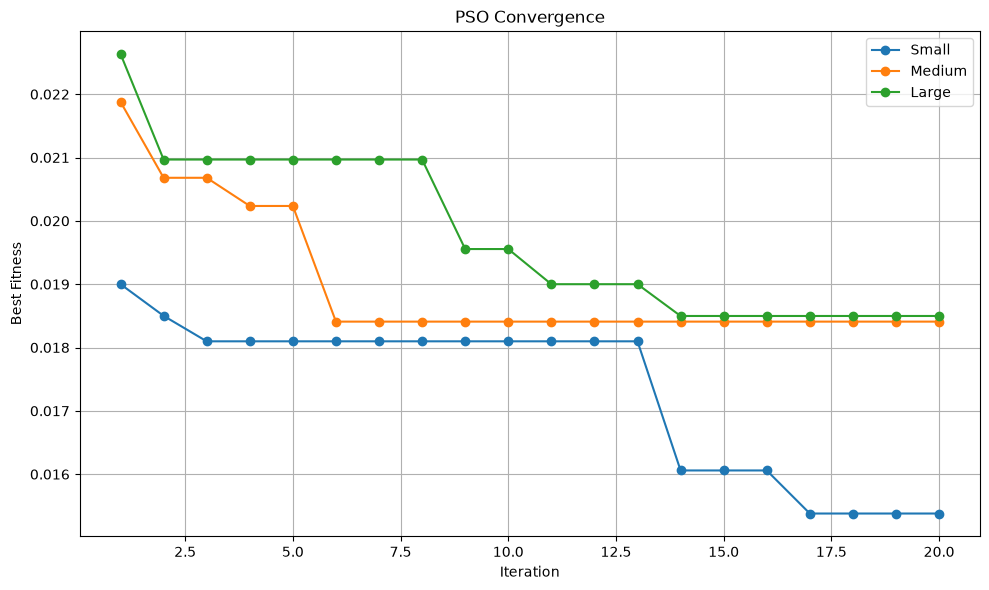

In [53]:
pso_small = [
    0.019000, 0.018500, 0.018098, 0.018098, 0.018098,
    0.018098, 0.018098, 0.018098, 0.018098, 0.018098,
    0.018098, 0.018098, 0.018098, 0.016059, 0.016059,
    0.016059, 0.015379, 0.015379, 0.015379, 0.015379
]

pso_medium = [
    0.021879, 0.020680, 0.020680, 0.020235, 0.020235,
    0.018409, 0.018409, 0.018409, 0.018409, 0.018409,
    0.018409, 0.018409, 0.018409, 0.018409, 0.018409,
    0.018409, 0.018409, 0.018409, 0.018409, 0.018409
]

pso_large = [
    0.022635, 0.020968, 0.020968, 0.020968, 0.020968,
    0.020968, 0.020968, 0.020968, 0.019555, 0.019555,
    0.019000, 0.019000, 0.019000, 0.018498, 0.018498,
    0.018498, 0.018498, 0.018498, 0.018498, 0.018498
]

iterations = range(1, 21)

plt.figure(figsize=(10, 6))

plt.plot(iterations, pso_small, marker="o", label="Small")
plt.plot(iterations, pso_medium, marker="o", label="Medium")
plt.plot(iterations, pso_large, marker="o", label="Large")

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

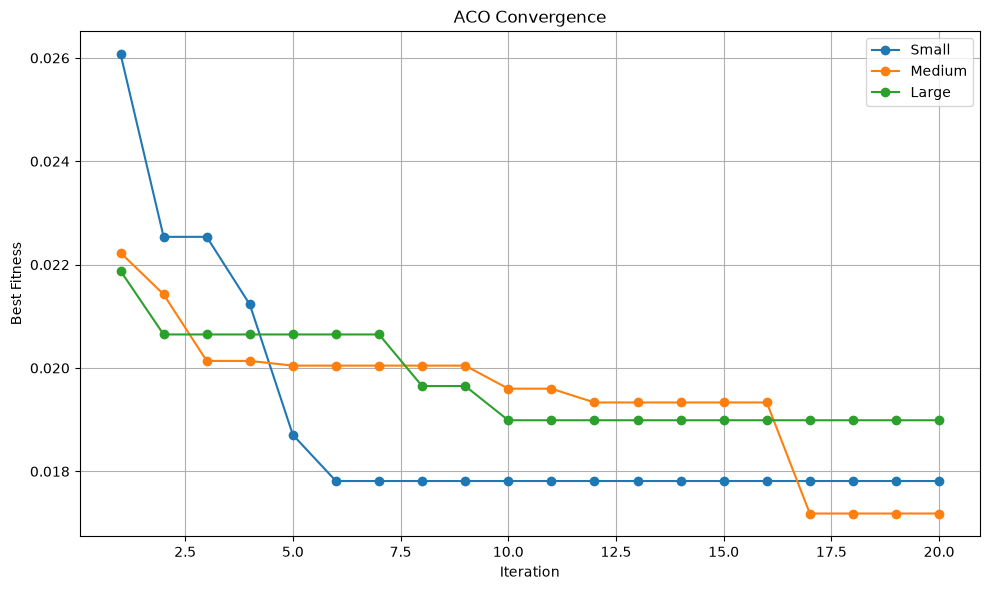

In [54]:
aco_small = [
    0.026077, 0.022538, 0.022538, 0.021230, 0.018706,
    0.017813, 0.017813, 0.017813, 0.017813, 0.017813,
    0.017813, 0.017813, 0.017813, 0.017813, 0.017813,
    0.017813, 0.017813, 0.017813, 0.017813, 0.017813
]

aco_medium = [
    0.022230, 0.021426, 0.020137, 0.020137, 0.020046,
    0.020046, 0.020046, 0.020046, 0.020046, 0.019600,
    0.019600, 0.019333, 0.019333, 0.019333, 0.019333,
    0.019333, 0.017184, 0.017184, 0.017184, 0.017184
]

aco_large = [
    0.021879, 0.020649, 0.020649, 0.020649, 0.020649,
    0.020649, 0.020649, 0.019651, 0.019651, 0.018989,
    0.018989, 0.018989, 0.018989, 0.018989, 0.018989,
    0.018989, 0.018989, 0.018989, 0.018989, 0.018989
]

iterations = range(1, 21)

plt.figure(figsize=(10, 6))

plt.plot(iterations, aco_small, marker="o", label="Small")
plt.plot(iterations, aco_medium, marker="o", label="Medium")
plt.plot(iterations, aco_large, marker="o", label="Large")

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("ACO Convergence")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Stability

In [55]:
import inspect

print("GA:")
print(inspect.signature(run_genetic_algorithm))

print("\nPSO:")
print(inspect.signature(run_particle_swarm_optimization))

print("\nACO:")
print(inspect.signature(run_ant_colony_optimization))

GA:
(problem_name, max_features, population_size=20, generations=20, crossover_rate=0.8, mutation_rate=0.01, tournament_size=3, elitism=1, random_seed=42)

PSO:
(problem_name, max_features, swarm_size=20, iterations=20, inertia=0.7, cognitive=1.5, social=1.5, random_seed=42)

ACO:
(problem_name, max_features, number_ants=20, iterations=20, evaporation_rate=0.5, pheromone_weight=1.0, pheromone_deposit=1.0, random_seed=42)


In [56]:
import inspect

print("GA return structure:")
print(inspect.getsource(run_genetic_algorithm)[-2000:])

print("\nPSO return structure:")
print(inspect.getsource(run_particle_swarm_optimization)[-2000:])

print("\nACO return structure:")
print(inspect.getsource(run_ant_colony_optimization)[-2000:])

GA return structure:
 = tournament_selection(
            population,
            fitness_values,
            tournament_size
        )

        new_population = []

        elite_indices = np.argsort(
            fitness_values
        )[:elitism]

        for index in elite_indices:
            new_population.append(
                population[index].copy()
            )

        while len(new_population) < population_size:

            parent_indices = np.random.choice(
                len(selected_population),
                size=2,
                replace=False
            )

            parent1 = selected_population[
                parent_indices[0]
            ]

            parent2 = selected_population[
                parent_indices[1]
            ]

            child1, child2 = crossover(
                parent1,
                parent2,
                crossover_rate
            )

            child1 = mutate(
                child1,
                mutation_rate
        